# VIGIA · Machine Learning & Modelling
Global Solution 2026.2 · FIAP · 1TIAPZ

Caio Ryan Velten Alves (572913) · João Vitor Fernandes Gomes (573882) · Igor Cypriano Moreno da Silva (570353)

O VIGIA propõe informar moradores sobre uma travessia sujeita a alagamento. Aqui estimamos **chuva acumulada de pelo menos 10 mm nas três horas seguintes** na região de São Paulo. O aviso local do VIGIA depende do nível medido pelo ESP32. A previsão é uma informação meteorológica complementar, associada aos ODS 11 e 13.

Fonte: [Open-Meteo Historical API](https://open-meteo.com/en/docs/historical-weather-api), modelo ERA5 do ECMWF, 2018–2024, UTC. A consulta pediu lat. −23,50 e lon. −46,62. A célula retornada é −23,50 e −46,50. ERA5 é reanálise em grade. Os valores representam a célula regional. A avaliação reproduz um histórico e não mede o desempenho operacional de previsões emitidas em tempo real.

,precipitation,temperature_2m,relative_humidity_2m,surface_pressure
time,,,,
2018-01-01 00:00:00+00:00,0.0,21.8,88,928.6
2018-01-01 01:00:00+00:00,0.0,21.5,88,929.1
2018-01-01 02:00:00+00:00,0.0,21.3,89,929.1
2018-01-01 03:00:00+00:00,0.0,20.7,95,929.1
2018-01-01 04:00:00+00:00,0.0,20.6,95,928.5


,precipitation,temperature_2m,relative_humidity_2m,surface_pressure
count,61368.00,61368.00,61368.00,61368.00
mean,0.15,20.44,79.00,932.62
std,0.58,4.60,16.92,3.35
min,0.00,2.20,13.00,920.80
25%,0.00,17.30,69.00,930.40
50%,0.00,20.30,85.00,932.40
75%,0.00,23.40,92.00,934.70
max,14.50,36.70,100.00,945.00


precipitation           0
temperature_2m          0
relative_humidity_2m    0
surface_pressure        0
Name: horas sem dado, dtype: int64

,count,sum,max
time,,,
2018,8760,1176.0,8.6
2019,8760,1204.9,9.6
2020,8784,1253.2,10.4
2021,8760,1086.7,7.7
2022,8760,1490.4,11.5
2023,8760,1364.7,14.5
2024,8784,1348.3,11.9


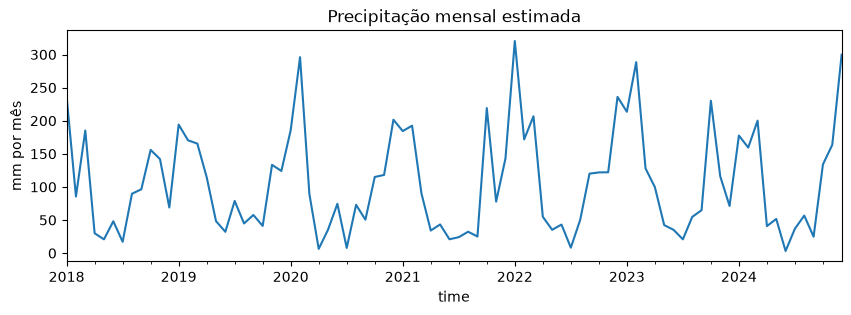

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve, precision_recall_fscore_support
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

source = json.loads(Path('dados/era5-sao-paulo-2018-2024.json').read_text(encoding='utf-8'))
weather = pd.DataFrame(source['hourly']).set_index('time')
weather.index = pd.to_datetime(weather.index, utc=True)
assert weather.index.is_unique and weather.index.is_monotonic_increasing
weather = weather.asfreq('h')
display(weather.head(), weather.describe().round(2))
display(weather.isna().sum().rename('horas sem dado'))
display(weather.groupby(weather.index.year).precipitation.agg(['count', 'sum', 'max']).round(2))
weather.precipitation.resample('MS').sum(min_count=1).plot(figsize=(10, 3), title='Precipitação mensal estimada')
plt.ylabel('mm por mês')
plt.show()

## Alvo e janelas
Às t horas usamos somente medições até t. Somamos as precipitações de t+1, t+2 e t+3 para construir o rótulo. Janelas futuras incompletas ficam de fora. O limiar de 10 mm em 3 h é operacional para este exercício. A série tem poucas horas acima de 10 mm isoladamente e nenhuma acima de 20 mm. A contagem descritiva por ano foi inspecionada para verificar se haveria exemplos positivos suficientes. O limiar de classificação dos modelos é ajustado somente em validação.

Treino 2018–2021, validação 2022–2023 e teste 2024. As três horas que antecedem cada fronteira são retiradas da partição anterior. O ajuste temporal da floresta aplica a mesma folga, medida no tempo e conferida para a grade horária.

In [2]:
LIMIT = 10
HORIZON = 3
future = sum(weather.precipitation.shift(-h) for h in range(1, HORIZON + 1))
features = weather.rename(columns={'precipitation': 'chuva_1h'}).copy()
for h in (3, 6, 24):
    features[f'chuva_{h}h'] = weather.precipitation.rolling(h, min_periods=h).sum()
features['variacao_pressao_3h'] = weather.surface_pressure.diff(3)
for name, values, period in [('hora', weather.index.hour, 24), ('mes', weather.index.month - 1, 12)]:
    features[f'{name}_sen'] = np.sin(2 * np.pi * values / period)
    features[f'{name}_cos'] = np.cos(2 * np.pi * values / period)

cut_val = pd.Timestamp('2022-01-01', tz='UTC')
cut_test = pd.Timestamp('2024-01-01', tz='UTC')
delta = pd.Timedelta(hours=HORIZON)
valid = future.notna()
X = features.loc[valid]
y = (future.loc[valid] >= LIMIT).astype(int)
train = X.index + delta < cut_val
val = (X.index >= cut_val) & (X.index + delta < cut_test)
test = X.index >= cut_test
Xtr, Xv, Xt = X.loc[train], X.loc[val], X.loc[test]
ytr, yv, yt = y.loc[train], y.loc[val], y.loc[test]
assert all(part.nunique() == 2 for part in [ytr, yv, yt])
display(pd.DataFrame([{'janela': n, 'horas': len(a), 'positivas': a.sum(), 'prevalência': a.mean()} for n, a in [('treino', ytr), ('validação', yv), ('teste', yt)]]))

,janela,horas,positivas,prevalência
0,treino,35061,136,0.003879
1,validação,17517,112,0.006394
2,teste,8781,54,0.006150


## Treinamento e comparação
A referência prevê a classe majoritária quando usa corte 0,5. A regressão logística fornece um modelo linear interpretável, com escalonamento dentro do pipeline. A Random Forest permite interações não lineares e usa imputação sem padronizar. A busca otimiza average precision, métrica que considera a ordenação de uma classe rara. O corte operacional maximiza F1 na validação. A escolha do modelo também usa somente a validação.

In [3]:
baseline = DummyClassifier(strategy='prior').fit(Xtr, ytr)
logistic = make_pipeline(SimpleImputer(), StandardScaler(), LogisticRegression(max_iter=600, class_weight='balanced', random_state=26)).fit(Xtr, ytr)
rf = make_pipeline(SimpleImputer(), RandomForestClassifier(n_estimators=70, class_weight='balanced_subsample', random_state=26, n_jobs=2))
folds = list(TimeSeriesSplit(n_splits=3, gap=HORIZON).split(Xtr))
assert all(Xtr.index[a[-1]] + delta < Xtr.index[b[0]] for a, b in folds)
search = GridSearchCV(rf, {'randomforestclassifier__max_depth': [5, 10], 'randomforestclassifier__min_samples_leaf': [8, 25]}, scoring='average_precision', cv=folds)
search.fit(Xtr, ytr)
print('Floresta selecionada:', search.best_params_, 'AP CV:', round(search.best_score_, 4))

def cutoff(actual, scores):
    p, r, thresholds = precision_recall_curve(actual, scores)
    f1 = np.divide(2*p[:-1]*r[:-1], p[:-1]+r[:-1], out=np.zeros(len(thresholds)), where=(p[:-1]+r[:-1])>0)
    return float(thresholds[np.argmax(f1)])

models = {'Referência': baseline, 'Regressão logística': logistic, 'Random Forest': search.best_estimator_}
rows = []
thresholds = {}
for name, model in models.items():
    thresholds[name] = 0.5 if name == 'Referência' else cutoff(yv, model.predict_proba(Xv)[:,1])
    for split, xf, yf in [('treino', Xtr, ytr), ('validação', Xv, yv), ('teste', Xt, yt)]:
        score = model.predict_proba(xf)[:,1]
        predicted = score >= thresholds[name]
        precision, recall, f1, _ = precision_recall_fscore_support(yf, predicted, average='binary', zero_division=0)
        tn, fp, fn, tp = confusion_matrix(yf, predicted, labels=[0, 1]).ravel()
        rows.append(dict(modelo=name, fase=split, AP=average_precision_score(yf, score), precisao=precision, recall=recall, F1=f1, FP=fp, FN=fn, TP=tp, TN=tn))
metrics = pd.DataFrame(rows)
winner = metrics[(metrics.fase=='validação') & (metrics.modelo!='Referência')].sort_values('AP', ascending=False).iloc[0].modelo
print('Escolhido pela AP na validação:', winner)
display(metrics.round(4))

Floresta selecionada: {'randomforestclassifier__max_depth': 10, 'randomforestclassifier__min_samples_leaf': 25} AP CV: 0.155


Escolhido pela AP na validação: Regressão logística


,modelo,fase,AP,precisao,recall,F1,FP,FN,TP,TN
0,Referência,treino,0.0039,0.0000,0.0000,0.0000,0,136,0,34925
1,Referência,validação,0.0064,0.0000,0.0000,0.0000,0,112,0,17405
2,Referência,teste,0.0061,0.0000,0.0000,0.0000,0,54,0,8727
3,Regressão logística,treino,0.1083,0.1245,0.2279,0.1610,218,105,31,34707
4,Regressão logística,validação,0.1639,0.2208,0.3036,0.2556,120,78,34,17285
5,Regressão logística,teste,0.1722,0.1944,0.2593,0.2222,58,40,14,8669
6,Random Forest,treino,0.4003,0.1418,0.9559,0.2469,787,6,130,34138
7,Random Forest,validação,0.1013,0.0934,0.4196,0.1528,456,65,47,16949
8,Random Forest,teste,0.1422,0.1049,0.5185,0.1745,239,26,28,8488


## Interpretação e episódio da demonstração
Calculamos importância por permutação na validação para verificar quais entradas mais influenciam o modelo. Variáveis correlacionadas podem dividir importância. O escore de modelos com pesos de classe não foi calibrado como probabilidade. Compare falsos avisos e eventos perdidos com a referência. A unidade das métricas é a **hora de emissão**. Janelas sobrepostas podem pertencer ao mesmo temporal.

In [4]:
model = models[winner]
importance = permutation_importance(model, Xv, yv, scoring='average_precision', n_repeats=3, random_state=26)
display(pd.Series(importance.importances_mean, index=X.columns).sort_values(ascending=False).head(8).round(4))
scores = model.predict_proba(Xt)[:,1]
pred = scores >= thresholds[winner]
entries = []
for label, mask in [('acerto', pred & (yt.to_numpy()==1)), ('falso_aviso', pred & (yt.to_numpy()==0)), ('evento_perdido', ~pred & (yt.to_numpy()==1))]:
    indices = np.flatnonzero(mask)
    if not len(indices):
        print('Sem exemplo:', label)
        continue
    i = indices[0]
    t = Xt.index[i]
    entries.append(dict(tipo=label, emitido_em_utc=t.isoformat(), horizonte_h=HORIZON, limiar_mm_3h=LIMIT, escore=float(scores[i]), corte=thresholds[winner], classe_prevista=int(pred[i]), acumulado_observado_era5_mm=round(float(future.loc[t]), 2), insumos={k:float(v) if pd.notna(v) else None for k,v in Xt.iloc[i].items()}))
display(pd.DataFrame(entries).drop(columns='insumos', errors='ignore'))
payload = {'modo':'reproducao_historica', 'modelo':winner, 'fonte':'ERA5 via Open-Meteo', 'latitude':source['latitude'], 'longitude':source['longitude'], 'episodios':entries}
Path('reproducao-ml.json').write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding='utf-8')
metrics.to_csv('metricas-ml.csv', index=False)


chuva_1h                0.1321
relative_humidity_2m    0.0582
chuva_3h                0.0343
temperature_2m          0.0323
surface_pressure        0.0170
hora_cos                0.0162
variacao_pressao_3h     0.0042
mes_cos                 0.0010
dtype: float64

,tipo,emitido_em_utc,horizonte_h,limiar_mm_3h,escore,corte,classe_prevista,acumulado_observado_era5_mm
0,acerto,2024-01-23T15:00:00+00:00,3,10,0.999178,0.998742,1,10.7
1,falso_aviso,2024-01-03T17:00:00+00:00,3,10,0.999997,0.998742,1,7.0
2,evento_perdido,2024-01-03T16:00:00+00:00,3,10,0.905031,0.998742,0,11.5


## Interpretação desta execução
A regressão logística foi escolhida pela AP da validação (0,164 contra 0,101 da Random Forest). No teste de 2024, a regressão teve AP de 0,172 contra 0,006 da referência, detectou 14 das 54 janelas positivas e gerou 58 falsos avisos. A floresta detectou 28 janelas positivas e gerou 239 falsos avisos. A queda da AP da floresta entre treino (0,400) e validação (0,101) sugere sobreajuste ou sensibilidade à mudança temporal. Chuva na última hora, umidade e chuva nas últimas três horas lideraram a importância por permutação. A demonstração mostra um acerto (10,7 mm), um falso aviso (7,0 mm) e um evento perdido (11,5 mm). Os valores vêm da reanálise ERA5.

## Limitações e integração
O painel pode ler o JSON de reprodução. Deve indicar o horário de emissão, a janela de três horas e o acumulado posteriormente estimado pela reanálise, distinguindo esse resultado do nível medido na travessia. A reanálise regional pode suavizar extremos locais. O exercício não valida previsão de cota, alagamento, funcionamento em campo ou ganhos para a população. Para uma avaliação operacional, seria preciso verificar medições locais e disponibilidade das entradas no momento da emissão. Antes de comparar com Redes Neurais, usar a mesma base e as mesmas fronteiras temporais.

## Vídeos e materiais da entrega

[Repositório com os arquivos da disciplina](https://github.com/Velten1/machine-learning-and-modelling-gs-2026-2)

[Vídeo de Machine Learning · 4 min 58 s](https://drive.google.com/file/d/1oqzxu0OJ2w-q37rjfVNTdDrXExXVLibJ/view)

[Vídeo de Redes Neurais · 3 min 28 s](https://drive.google.com/file/d/1wOi7uYgDDL4ATO8dc5K9xpFv59M8KZYa/view)